In [1]:
%pip install pandas numpy matplotlib scikit-learn joblib mlflow

Note: you may need to restart the kernel to use updated packages.


In [2]:
from pathlib import Path
import os
import json
import warnings

import joblib
import mlflow
import mlflow.sklearn
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    fbeta_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    PrecisionRecallDisplay,
    classification_report
)

warnings.filterwarnings("default")

# Your project directory
PROJECT_ROOT = Path(
    r"C:\Users\Tanish.Ranjan\OneDrive - ENCORA\Desktop\fraud-detection-system"
)

if not PROJECT_ROOT.exists():
    raise FileNotFoundError(
        f"Project folder not found: {PROJECT_ROOT}\n"
        "Update PROJECT_ROOT to your actual project location."
    )

os.chdir(PROJECT_ROOT)

# Existing project files
MODEL_PATH = PROJECT_ROOT / "models" / "fraud_detection_pipeline.pkl"

FEATURE_DATA_PATH = (
    PROJECT_ROOT / "data" / "processed" /
    "transactions_features.csv.gz"
)

SPLIT_CONFIG_PATH = (
    PROJECT_ROOT / "notebooks" / "outputs" /
    "split_config.json"
)

OUTPUT_DIR = PROJECT_ROOT / "notebooks" / "outputs"
PLOT_DIR = OUTPUT_DIR / "phase3_plots"

# Local MLflow database
MLFLOW_DB = PROJECT_ROOT / "mlflow.db"
EXPERIMENT_NAME = "fraud-detection-local"

EXPECTED_FEATURES = [
    "type",
    "amount",
    "oldbalanceOrg",
    "oldbalanceDest",
    "hour_of_day",
    "night_flag",
    "amount_to_origin_balance_ratio",
    "origin_balance_was_zero",
    "origin_txn_count_prior_steps"
]

TARGET_COLUMN = "isFraud"
TIME_COLUMN = "step"

print("Project root:", PROJECT_ROOT)
print("Model exists:", MODEL_PATH.exists())
print("Feature dataset exists:", FEATURE_DATA_PATH.exists())
print("Split configuration exists:", SPLIT_CONFIG_PATH.exists())

Project root: C:\Users\Tanish.Ranjan\OneDrive - ENCORA\Desktop\fraud-detection-system
Model exists: True
Feature dataset exists: True
Split configuration exists: True


In [3]:
if not MODEL_PATH.exists():
    raise FileNotFoundError(f"Model not found: {MODEL_PATH}")

# Correct loading method for your saved model bundle
saved_bundle = joblib.load(MODEL_PATH)

if not isinstance(saved_bundle, dict):
    raise TypeError(
        f"Expected a dictionary model bundle, got {type(saved_bundle)}"
    )

required_keys = {
    "pipeline",
    "threshold",
    "feature_columns",
    "target_column"
}

missing_keys = required_keys - set(saved_bundle.keys())

if missing_keys:
    raise KeyError(
        f"Missing keys in model bundle: {missing_keys}"
    )

# Extract the actual model and metadata
pipeline = saved_bundle["pipeline"]

threshold = float(saved_bundle["threshold"])

feature_columns = list(
    saved_bundle["feature_columns"]
)

target_column = saved_bundle.get(
    "target_column", TARGET_COLUMN
)

time_column = saved_bundle.get(
    "time_column", TIME_COLUMN
)

training_cutoff_step = int(
    saved_bundle.get(
        "outer_training_cutoff_step",
        saved_bundle.get("training_cutoff_step", 594)
    )
)

model_name = saved_bundle.get(
    "model_name", "Saved fraud detection pipeline"
)

if feature_columns != EXPECTED_FEATURES:
    raise ValueError(
        "The saved feature list does not match the expected list.\n"
        f"Saved: {feature_columns}\n"
        f"Expected: {EXPECTED_FEATURES}"
    )

if not hasattr(pipeline, "predict_proba"):
    raise TypeError(
        "The loaded pipeline does not support predict_proba()."
    )

print("Model loaded successfully!")
print("Model name:", model_name)
print("Pipeline type:", type(pipeline))
print("Threshold:", threshold)
print("Training cutoff:", training_cutoff_step)
print("Features:", feature_columns)

Model loaded successfully!
Model name: Random Forest (balanced)
Pipeline type: <class 'sklearn.pipeline.Pipeline'>
Threshold: 0.7999999999999999
Training cutoff: 594
Features: ['type', 'amount', 'oldbalanceOrg', 'oldbalanceDest', 'hour_of_day', 'night_flag', 'amount_to_origin_balance_ratio', 'origin_balance_was_zero', 'origin_txn_count_prior_steps']


In [4]:
if not SPLIT_CONFIG_PATH.exists():
    raise FileNotFoundError(
        f"Split configuration not found: {SPLIT_CONFIG_PATH}"
    )

with open(SPLIT_CONFIG_PATH, "r", encoding="utf-8") as file:
    split_config = json.load(file)

print(json.dumps(split_config, indent=2))

if split_config.get("split_method") != "chronological_by_step":
    raise ValueError(
        "Expected a chronological_by_step split."
    )

cutoff_step = int(split_config["cutoff_step"])

if cutoff_step != training_cutoff_step:
    raise ValueError(
        f"Split cutoff ({cutoff_step}) and model cutoff "
        f"({training_cutoff_step}) do not match."
    )

expected_test_rows = int(
    split_config.get("test_rows", 0)
)

expected_min_step = int(
    split_config.get("test_step_min", cutoff_step + 1)
)

expected_max_step = int(
    split_config.get("test_step_max", 10**9)
)

print(f"Training period: step <= {cutoff_step}")
print(f"Test period: step > {cutoff_step}")
print(f"Expected test rows: {expected_test_rows:,}")

{
  "dataset_path": "data/processed/transactions_features.csv.gz",
  "target_column": "isFraud",
  "time_column": "step",
  "split_method": "chronological_by_step",
  "train_rule": "step <= 594",
  "test_rule": "step > 594",
  "cutoff_step": 594,
  "train_step_min": 1,
  "train_step_max": 594,
  "test_step_min": 595,
  "test_step_max": 743,
  "train_rows": 6239040,
  "test_rows": 123580,
  "random_split": false,
  "resampling_applied": false,
  "exclude_from_initial_features": [
    "isFraud",
    "isFlaggedFraud",
    "nameOrig",
    "nameDest"
  ]
}
Training period: step <= 594
Test period: step > 594
Expected test rows: 123,580


In [5]:
if not FEATURE_DATA_PATH.exists():
    raise FileNotFoundError(
        f"Dataset not found: {FEATURE_DATA_PATH}"
    )

required_columns = (
    feature_columns + [target_column, time_column]
)

# Read the CSV header first to validate columns
available_columns = set(
    pd.read_csv(
        FEATURE_DATA_PATH,
        compression="infer",
        nrows=0
    ).columns
)

missing_columns = [
    column for column in required_columns
    if column not in available_columns
]

if missing_columns:
    raise ValueError(
        f"Missing dataset columns: {missing_columns}"
    )

test_parts = []
chunk_size = 250_000

for chunk_number, chunk in enumerate(
    pd.read_csv(
        FEATURE_DATA_PATH,
        compression="infer",
        usecols=required_columns,
        chunksize=chunk_size
    ),
    start=1
):
    # Select the held-out chronological test period
    test_chunk = chunk.loc[
        chunk[time_column] > cutoff_step
    ]

    if not test_chunk.empty:
        test_parts.append(test_chunk.copy())

    print(
        f"Processed chunk {chunk_number}; "
        f"held-out rows collected: "
        f"{sum(len(part) for part in test_parts):,}",
        end="\r"
    )

if not test_parts:
    raise ValueError(
        "No held-out test rows were found."
    )

test_df = pd.concat(
    test_parts,
    ignore_index=True
)

del test_parts

# Validate against saved split configuration
if expected_test_rows and len(test_df) != expected_test_rows:
    raise ValueError(
        f"Expected {expected_test_rows:,} test rows, "
        f"but found {len(test_df):,}."
    )

if int(test_df[time_column].min()) != expected_min_step:
    raise ValueError(
        f"Unexpected minimum test step: "
        f"{test_df[time_column].min()}"
    )

if int(test_df[time_column].max()) != expected_max_step:
    raise ValueError(
        f"Unexpected maximum test step: "
        f"{test_df[time_column].max()}"
    )

X_test = test_df[feature_columns].copy()

y_test = test_df[target_column].astype(int).copy()

if not set(y_test.unique()).issubset({0, 1}):
    raise ValueError(
        "The target column must contain only 0 and 1."
    )

if y_test.nunique() != 2:
    raise ValueError(
        "The held-out test set must contain both classes."
    )

print("\n\nTest data loaded successfully!")
print("Test rows:", f"{len(test_df):,}")
print(
    "Test steps:",
    int(test_df[time_column].min()),
    "to",
    int(test_df[time_column].max())
)
print("Actual fraud cases:", f"{int(y_test.sum()):,}")
print("Fraud rate:", f"{y_test.mean():.4%}")
print("Test feature shape:", X_test.shape)

Processed chunk 26; held-out rows collected: 123,580

Test data loaded successfully!
Test rows: 123,580
Test steps: 595 to 743
Actual fraud cases: 1,654
Fraud rate: 1.3384%
Test feature shape: (123580, 9)


In [6]:
# Generate fraud probabilities
y_prob = pipeline.predict_proba(X_test)[:, 1]

if not np.isfinite(y_prob).all():
    raise ValueError(
        "Predicted probabilities contain NaN or infinite values."
    )

# Use the saved decision threshold
y_pred = (y_prob >= threshold).astype(int)

# Confusion matrix
tn, fp, fn, tp = confusion_matrix(
    y_test,
    y_pred,
    labels=[0, 1]
).ravel()

# Calculate evaluation metrics
metrics = {
    "decision_threshold": float(threshold),
    "test_rows": int(len(y_test)),
    "actual_fraud_count": int(y_test.sum()),
    "predicted_fraud_count": int(y_pred.sum()),
    "fraud_rate": float(y_test.mean()),
    "precision": float(
        precision_score(y_test, y_pred, zero_division=0)
    ),
    "recall": float(
        recall_score(y_test, y_pred, zero_division=0)
    ),
    "f1_score": float(
        f1_score(y_test, y_pred, zero_division=0)
    ),
    "f2_score": float(
        fbeta_score(
            y_test, y_pred, beta=2, zero_division=0
        )
    ),
    "roc_auc": float(
        roc_auc_score(y_test, y_prob)
    ),
    "average_precision": float(
        average_precision_score(y_test, y_prob)
    ),
    "true_negative": int(tn),
    "false_positive": int(fp),
    "false_negative": int(fn),
    "true_positive": int(tp)
}

metrics_df = pd.DataFrame(
    list(metrics.items()),
    columns=["Metric", "Value"]
)

display(metrics_df)

print("\nClassification report:")
print(
    classification_report(
        y_test,
        y_pred,
        target_names=["Not Fraud", "Fraud"],
        zero_division=0
    )
)

,Metric,Value
0,decision_threshold,0.800000
1,test_rows,123580.000000
2,actual_fraud_count,1654.000000
3,predicted_fraud_count,1539.000000
4,fraud_rate,0.013384
5,precision,0.942170
6,recall,0.876663
7,f1_score,0.908237
8,f2_score,0.889025
9,roc_auc,0.999045



Classification report:
              precision    recall  f1-score   support

   Not Fraud       1.00      1.00      1.00    121926
       Fraud       0.94      0.88      0.91      1654

    accuracy                           1.00    123580
   macro avg       0.97      0.94      0.95    123580
weighted avg       1.00      1.00      1.00    123580



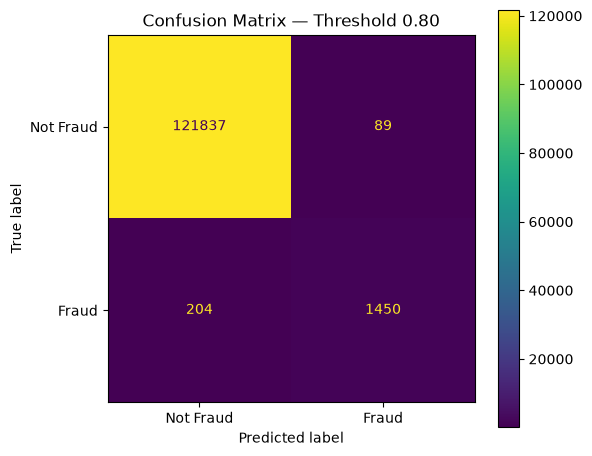

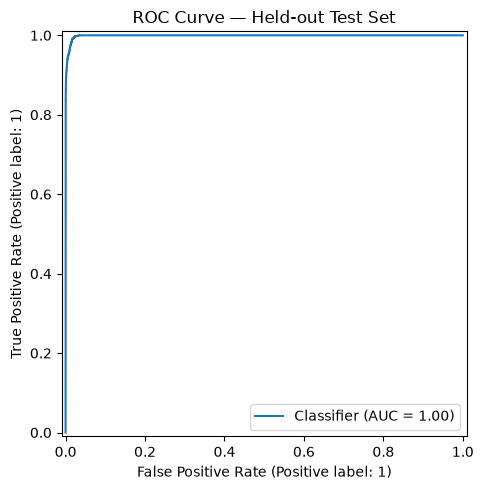

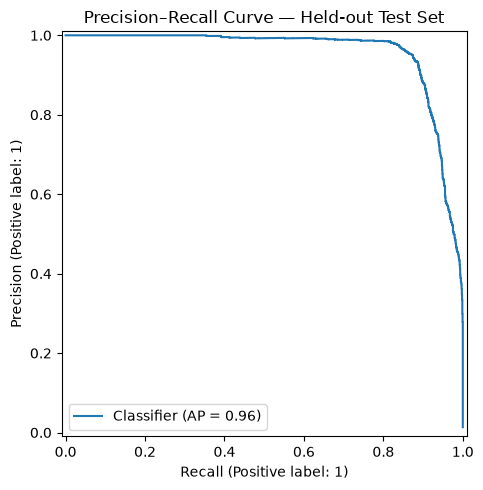

Metrics and plots saved successfully.
Metrics JSON: C:\Users\Tanish.Ranjan\OneDrive - ENCORA\Desktop\fraud-detection-system\notebooks\outputs\phase3_heldout_metrics.json
Metrics CSV: C:\Users\Tanish.Ranjan\OneDrive - ENCORA\Desktop\fraud-detection-system\notebooks\outputs\phase3_heldout_metrics.csv
Plots folder: C:\Users\Tanish.Ranjan\OneDrive - ENCORA\Desktop\fraud-detection-system\notebooks\outputs\phase3_plots


In [7]:
OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

PLOT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

# Save evaluation metrics
metrics_json_path = (
    OUTPUT_DIR / "phase3_heldout_metrics.json"
)

metrics_csv_path = (
    OUTPUT_DIR / "phase3_heldout_metrics.csv"
)

metrics_json_path.write_text(
    json.dumps(metrics, indent=2, allow_nan=False),
    encoding="utf-8"
)

pd.DataFrame([metrics]).to_csv(
    metrics_csv_path,
    index=False
)

# 1. Confusion matrix
cm_path = PLOT_DIR / "confusion_matrix.png"

fig, ax = plt.subplots(figsize=(6, 5))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    labels=[0, 1],
    display_labels=["Not Fraud", "Fraud"],
    values_format="d",
    ax=ax
)

ax.set_title(f"Confusion Matrix — Threshold {threshold:.2f}")
fig.tight_layout()
fig.savefig(cm_path, dpi=150, bbox_inches="tight")
plt.show()
plt.close(fig)

# 2. ROC curve
roc_path = PLOT_DIR / "roc_curve.png"

fig, ax = plt.subplots(figsize=(6, 5))

RocCurveDisplay.from_predictions(
    y_test,
    y_prob,
    ax=ax
)

ax.set_title("ROC Curve — Held-out Test Set")
fig.tight_layout()
fig.savefig(roc_path, dpi=150, bbox_inches="tight")
plt.show()
plt.close(fig)

# 3. Precision-recall curve
pr_path = PLOT_DIR / "precision_recall_curve.png"

fig, ax = plt.subplots(figsize=(6, 5))

PrecisionRecallDisplay.from_predictions(
    y_test,
    y_prob,
    ax=ax
)

ax.set_title("Precision–Recall Curve — Held-out Test Set")
fig.tight_layout()
fig.savefig(pr_path, dpi=150, bbox_inches="tight")
plt.show()
plt.close(fig)

print("Metrics and plots saved successfully.")
print("Metrics JSON:", metrics_json_path)
print("Metrics CSV:", metrics_csv_path)
print("Plots folder:", PLOT_DIR)

In [8]:
# Configure local MLflow tracking
tracking_uri = f"sqlite:///{MLFLOW_DB.as_posix()}"

mlflow.set_tracking_uri(tracking_uri)

mlflow.set_experiment(EXPERIMENT_NAME)

with mlflow.start_run(
    run_name="saved-pipeline-heldout-evaluation"
) as active_run:

    # Run identification
    mlflow.set_tag(
        "phase",
        "phase3_local_mlflow"
    )

    mlflow.set_tag(
        "evaluation_scope",
        "chronological_heldout_test"
    )

    mlflow.set_tag(
        "model_name",
        str(model_name)
    )

    # Parameters
    mlflow.log_param(
        "model_path",
        str(MODEL_PATH.relative_to(PROJECT_ROOT))
    )

    mlflow.log_param(
        "dataset_path",
        str(FEATURE_DATA_PATH.relative_to(PROJECT_ROOT))
    )

    mlflow.log_param(
        "split_method",
        split_config["split_method"]
    )

    mlflow.log_param(
        "cutoff_step",
        cutoff_step
    )

    mlflow.log_param(
        "decision_threshold",
        threshold
    )

    mlflow.log_param(
        "feature_count",
        len(feature_columns)
    )

    mlflow.log_param(
        "training_performed",
        False
    )

    # Evaluation metrics
    for metric_name, metric_value in metrics.items():
        mlflow.log_metric(
            metric_name,
            float(metric_value)
        )

    # Evaluation artifacts
    for artifact_path in [
        metrics_json_path,
        metrics_csv_path,
        cm_path,
        roc_path,
        pr_path
    ]:
        mlflow.log_artifact(
            str(artifact_path),
            artifact_path="evaluation"
        )

    run_id = active_run.info.run_id

print("MLflow logging completed!")
print("Tracking URI:", tracking_uri)
print("Experiment:", EXPERIMENT_NAME)
print("Run ID:", run_id)

c:\Users\Tanish.Ranjan\OneDrive - ENCORA\Desktop\fraud-detection-system\.venv\Lib\site-packages\mlflow\store\tracking\sqlalchemy_store.py:327: SADeprecationWarning: The ``noload`` loader strategy is deprecated and will be removed in a future release.  This option produces incorrect results by returning ``None`` for related items. (deprecated since: 2.1)
  sqlalchemy.orm.configure_mappers()


MLflow logging completed!
Tracking URI: sqlite:///C:/Users/Tanish.Ranjan/OneDrive - ENCORA/Desktop/fraud-detection-system/mlflow.db
Experiment: fraud-detection-local
Run ID: c75734bf217945a3aa0666370b60de76


In [9]:
from mlflow.tracking import MlflowClient

client = MlflowClient(
    tracking_uri=tracking_uri
)

experiment = client.get_experiment_by_name(
    EXPERIMENT_NAME
)

if experiment is None:
    raise RuntimeError(
        "MLflow experiment was not found."
    )

logged_run = client.get_run(run_id)

print("Experiment name:", experiment.name)
print("Experiment ID:", experiment.experiment_id)
print("Run ID:", logged_run.info.run_id)
print("Run status:", logged_run.info.status)

print("\nLogged metrics:")
for name, value in sorted(logged_run.data.metrics.items()):
    print(f"{name}: {value}")

print("\nLogged parameters:")
for name, value in sorted(logged_run.data.params.items()):
    print(f"{name}: {value}")

Experiment name: fraud-detection-local
Experiment ID: 1
Run ID: c75734bf217945a3aa0666370b60de76
Run status: FINISHED

Logged metrics:
actual_fraud_count: 1654.0
average_precision: 0.9567231691205053
decision_threshold: 0.7999999999999999
f1_score: 0.9082367679298465
f2_score: 0.8890251379521765
false_negative: 204.0
false_positive: 89.0
fraud_rate: 0.01338404272536009
precision: 0.9421702404158544
predicted_fraud_count: 1539.0
recall: 0.8766626360338573
roc_auc: 0.9990449189342173
test_rows: 123580.0
true_negative: 121837.0
true_positive: 1450.0

Logged parameters:
cutoff_step: 594
dataset_path: data\processed\transactions_features.csv.gz
decision_threshold: 0.7999999999999999
feature_count: 9
model_path: models\fraud_detection_pipeline.pkl
split_method: chronological_by_step
training_performed: False


In [10]:
print("PHASE 3 LOCAL MLflow EVALUATION COMPLETE")
print("=" * 50)

print(f"Model: {model_name}")
print(f"Threshold: {threshold:.2f}")
print(f"Test rows: {len(y_test):,}")
print(f"Actual fraud cases: {int(y_test.sum()):,}")
print(f"Predicted fraud cases: {int(y_pred.sum()):,}")

print(f"\nPrecision: {metrics['precision']:.4f}")
print(f"Recall: {metrics['recall']:.4f}")
print(f"F1 score: {metrics['f1_score']:.4f}")
print(f"F2 score: {metrics['f2_score']:.4f}")
print(f"ROC AUC: {metrics['roc_auc']:.4f}")
print(f"Average precision: {metrics['average_precision']:.4f}")

print("\nMetrics saved to:")
print(metrics_csv_path)

print("\nMLflow experiment:")
print(f"http://127.0.0.1:5000")

PHASE 3 LOCAL MLflow EVALUATION COMPLETE
Model: Random Forest (balanced)
Threshold: 0.80
Test rows: 123,580
Actual fraud cases: 1,654
Predicted fraud cases: 1,539

Precision: 0.9422
Recall: 0.8767
F1 score: 0.9082
F2 score: 0.8890
ROC AUC: 0.9990
Average precision: 0.9567

Metrics saved to:
C:\Users\Tanish.Ranjan\OneDrive - ENCORA\Desktop\fraud-detection-system\notebooks\outputs\phase3_heldout_metrics.csv

MLflow experiment:
http://127.0.0.1:5000
